<a href="https://colab.research.google.com/github/IntanLestari19/Tugas-ProbabilitasDanStatistika/blob/main/Tugas_Eksplorasi_Python/Code_Probabilitas_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Implementasi Python: Probabilitas
Jalankan sel pertama (import library) lebih dulu, lalu sel lainnya berurutan. Komentar `# library ...` menandai baris yang memakai library tertentu.

In [ ]:
# import library bawaan Python
import math
# import library bawaan Python
import itertools
# import library bawaan Python
import random
# import library bawaan Python
import statistics
# import library bawaan Python (Counter)
from collections import Counter
# import library bawaan Python (Fraction)
from fractions import Fraction
# import library numpy: array dan bilangan acak
import numpy as np
# import library pandas: tabel data
import pandas as pd
# import library matplotlib: grafik
import matplotlib.pyplot as plt
# import library scipy.stats: distribusi dan uji statistik
from scipy import stats
# import library scikit-learn: model Naive Bayes
from sklearn.naive_bayes import MultinomialNB
# import library scikit-learn: pengubah teks menjadi angka
from sklearn.feature_extraction.text import CountVectorizer

rng = np.random.default_rng(1)   # library numpy: generator acak untuk simulasi

math         : 10 20 120
itertools    : [('A', 'B'), ('A', 'C'), ('B', 'C')]
random       : 2
fractions    : 1/6
collections  : Counter({'b': 3, 'a': 2, 'c': 1})
statistics   : 2 1.0
numpy        : [2 1 2 1 0]
pandas       :
klik       tidak  ya
perangkat           
desktop        0   1
mobile         1   1
scipy.stats  : 0.3487 1.6449
scikit-learn : [1]


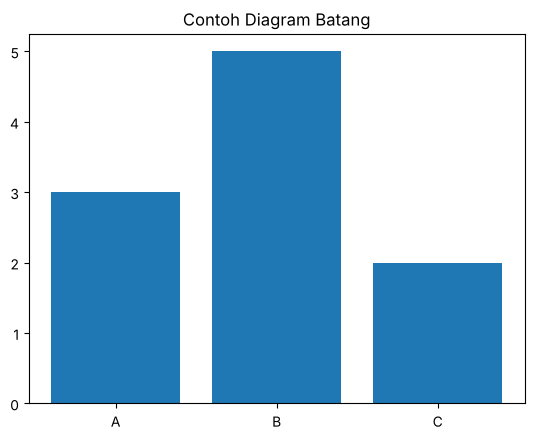

In [ ]:
# A | Eksplorasi Library Python: contoh pemakaian tiap library
# library math: factorial(n) menghitung faktorial (FACT di Excel)
# library math: perm(n, r) menghitung permutasi (PERMUT di Excel)
# library math: comb(n, r) menghitung kombinasi (COMBIN di Excel)
print("math         :", math.comb(5, 2), math.perm(5, 2), math.factorial(5))
# library itertools: combinations() mendaftar semua kombinasi
print("itertools    :", list(itertools.combinations("ABC", 2)))
# library random: seed() mengunci hasil acak
random.seed(1)
# library random: randint(a, b) membuat bilangan bulat acak
print("random       :", random.randint(1, 6))
# library fractions: Fraction() menyimpan peluang sebagai pecahan eksak
print("fractions    :", Fraction(1, 6))
# library collections: Counter() menghitung frekuensi tiap nilai
print("collections  :", Counter("aabbbc"))
# library statistics: mean() menghitung rata-rata
# library statistics: stdev() menghitung simpangan baku sampel
print("statistics   :", statistics.mean([1, 2, 3]), statistics.stdev([1, 2, 3]))
# library numpy: default_rng() membuat generator bilangan acak
rng = np.random.default_rng(42)
# library numpy: rng.binomial() membangkitkan data acak
print("numpy        :", rng.binomial(10, 0.1, size=5))
# library pandas: DataFrame() membuat tabel data
data = pd.DataFrame({"perangkat": ["mobile", "mobile", "desktop"], "klik": ["ya", "tidak", "ya"]})
print("pandas       :")
# library pandas: crosstab() membuat tabel kontingensi
print(pd.crosstab(data["perangkat"], data["klik"]))
# library scipy.stats: objek distribusi binom
# library scipy.stats: .pmf() menghitung peluang dari distribusi
print("scipy.stats  :", round(stats.binom(10, 0.1).pmf(0), 4), round(stats.norm.ppf(0.95), 4))
# library scikit-learn: CountVectorizer mengubah teks menjadi hitungan kata
cv = CountVectorizer()
# library scikit-learn: CountVectorizer mengubah teks menjadi hitungan kata
X = cv.fit_transform(["gratis klik", "rapat tim"])
# library scikit-learn: MultinomialNB() membuat model Naive Bayes
model = MultinomialNB().fit(X, [1, 0])
# library scikit-learn: CountVectorizer mengubah teks menjadi hitungan kata
# library scikit-learn: model.predict() pada model Naive Bayes
print("scikit-learn :", model.predict(cv.transform(["gratis klik"])))

# library matplotlib: plt.bar() untuk grafik
plt.bar(["A", "B", "C"], [3, 5, 2])
# library matplotlib: plt.title() untuk grafik
plt.title("Contoh Diagram Batang")
# library matplotlib: plt.show() untuk grafik
plt.show()

## 1. Probabilitas Dasar
**Contoh 1: Menebak PIN Dua Digit**

Sebuah aplikasi memakai PIN yang terdiri dari dua digit angka, dan setiap digit dapat bernilai 0 sampai 9. Seorang peretas menebak PIN secara acak, dengan setiap kemungkinan PIN sama mungkin.

n(S) = 100 | n(B) = 10
P(A) = 1/100 = 0.01
P(B) = 1/10 = 0.1
Kembar: 510 | tidak kembar: 4490
Frekuensi relatif kembar = 0.102


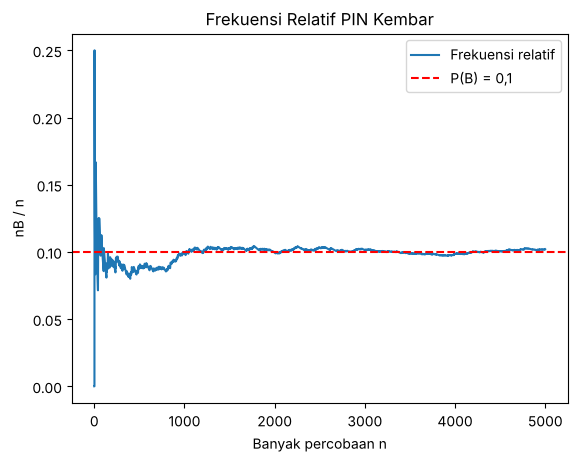

In [ ]:
# B.1 | Probabilitas Dasar | Contoh 1: Menebak PIN Dua Digit
# Ruang sampel: semua pasangan dua digit
# library itertools: product() membuat semua pasangan berurutan (dengan pengembalian)
S = list(itertools.product("0123456789", repeat=2))
n_S = len(S)
B = [h for h in S if h[0] == h[1]]                # PIN dengan dua digit sama
# library fractions: Fraction() menyimpan peluang sebagai pecahan eksak
p_A = Fraction(1, n_S)                            # pecahan eksak
# library fractions: Fraction() menyimpan peluang sebagai pecahan eksak
p_B = Fraction(len(B), n_S)
print("n(S) =", n_S, "| n(B) =", len(B))
print("P(A) =", p_A, "=", float(p_A))
print("P(B) =", p_B, "=", float(p_B))

# Definisi frekuensi relatif: 5.000 tebakan acak
# library random: seed() mengunci hasil acak
random.seed(1)
n = 5000
# library random: randint(a, b) membuat bilangan bulat acak
kembar = [random.randint(0, 9) == random.randint(0, 9) for _ in range(n)]
# library collections: Counter() menghitung frekuensi tiap nilai
hitung = Counter(kembar)
print("Kembar:", hitung[True], "| tidak kembar:", hitung[False])
print("Frekuensi relatif kembar =", hitung[True] / n)

# Grafik: frekuensi relatif mendekati P(B) saat n bertambah
# library numpy: np.cumsum() operasi array
frek_relatif = np.cumsum(kembar) / np.arange(1, n + 1)
# library matplotlib: plt.plot() untuk grafik
plt.plot(frek_relatif, label="Frekuensi relatif")
# library matplotlib: plt.axhline() untuk grafik
plt.axhline(0.1, color="red", linestyle="--", label="P(B) = 0,1")
# library matplotlib: plt.xlabel() untuk grafik
plt.xlabel("Banyak percobaan n")
# library matplotlib: plt.ylabel() untuk grafik
plt.ylabel("nB / n")
# library matplotlib: plt.title() untuk grafik
plt.title("Frekuensi Relatif PIN Kembar")
# library matplotlib: plt.legend() untuk grafik
plt.legend()
# library matplotlib: plt.show() untuk grafik
plt.show()


## 2. Permutasi dan Kombinasi
**Contoh 1: Memilih Dua Server untuk Pembaruan Sistem**

Sebuah tim memiliki 4 server, yaitu A, B, C, dan D. Tim memilih 2 server untuk menjalankan pembaruan sistem. Pada beberapa skenario, server pertama berperan sebagai server utama dan server kedua sebagai server cadangan, sehingga urutan penting.

In [ ]:
# B.2 | Permutasi dan Kombinasi | Contoh 1: Memilih Dua Server untuk Pembaruan Sistem
server = ["A", "B", "C", "D"]
n, r = 4, 2

# Dengan rumus: faktorial, permutasi, dan kombinasi
# library math: factorial(n) menghitung faktorial (FACT di Excel)
print("4! =", math.factorial(n))
print("Kasus 1 (urutan, dengan pengembalian)   :", n ** r)
# library math: perm(n, r) menghitung permutasi (PERMUT di Excel)
print("Kasus 2 (urutan, tanpa pengembalian)    :", math.perm(n, r))
# library math: comb(n, r) menghitung kombinasi (COMBIN di Excel)
print("Kasus 3 (tanpa urutan, tanpa pengembalian):", math.comb(n, r))
# library math: comb(n, r) menghitung kombinasi (COMBIN di Excel)
print("Kasus 4 (tanpa urutan, dengan pengembalian):", math.comb(n + r - 1, r))

# Membuktikan dengan mendaftar semua susunan
# library itertools: product() membuat semua pasangan berurutan (dengan pengembalian)
k1 = list(itertools.product(server, repeat=r))
# library itertools: permutations() mendaftar semua permutasi
k2 = list(itertools.permutations(server, r))
# library itertools: combinations() mendaftar semua kombinasi
k3 = list(itertools.combinations(server, r))
# library itertools: combinations_with_replacement() mendaftar kombinasi dengan pengembalian
k4 = list(itertools.combinations_with_replacement(server, r))
print("Banyak susunan hasil daftar:", len(k1), len(k2), len(k3), len(k4))
print("Daftar kasus 3:", k3)

# Peluang server terpilih adalah A dan B
# library fractions: Fraction() menyimpan peluang sebagai pecahan eksak
p_E = Fraction(1, len(k3))
print("P(E) =", p_E, "=", round(float(p_E), 4))


4! = 24
Kasus 1 (urutan, dengan pengembalian)   : 16
Kasus 2 (urutan, tanpa pengembalian)    : 12
Kasus 3 (tanpa urutan, tanpa pengembalian): 6
Kasus 4 (tanpa urutan, dengan pengembalian): 10
Banyak susunan hasil daftar: 16 12 6 10
Daftar kasus 3: [('A', 'B'), ('A', 'C'), ('A', 'D'), ('B', 'C'), ('B', 'D'), ('C', 'D')]
P(E) = 1/6 = 0.1667


## 3. Probabilitas Gabungan
**Contoh 1: Insiden Phishing dan Malware**

Tim keamanan sebuah perusahaan mencatat 200 insiden siber selama setahun. Sebanyak 80 insiden melibatkan phishing, 50 insiden melibatkan malware, dan 20 insiden melibatkan phishing sekaligus malware. Satu insiden dipilih secara acak.

In [ ]:
# B.3 | Probabilitas Gabungan | Contoh 1: Insiden Phishing dan Malware
# library numpy: default_rng() membuat generator bilangan acak
rng = np.random.default_rng(42)

# Insiden dinomori 0 sampai 199.
# Phishing = 0..79 dan malware = 60..109, irisannya 60..79 (20 insiden)
phishing = set(range(0, 80))
malware = set(range(60, 110))
n_S = 200
p_P, p_M = len(phishing) / n_S, len(malware) / n_S
p_irisan = len(phishing & malware) / n_S
p_gabungan = p_P + p_M - p_irisan               # dengan rumus
p_himpunan = len(phishing | malware) / n_S      # dengan operasi himpunan
print("P(P) =", p_P, "| P(M) =", p_M, "| P(P irisan M) =", p_irisan)
print("P(P gabungan M) dengan rumus     =", p_gabungan)
print("P(P gabungan M) dengan himpunan  =", p_himpunan)

# Kejadian saling lepas: irisan kosong sehingga peluang cukup dijumlahkan
rendah = set(range(0, 90))
tinggi = set(range(90, 150))
print("Irisan R dan T kosong:", len(rendah & tinggi) == 0)
print("P(R gabungan T) =", len(rendah) / n_S + len(tinggi) / n_S)

# Simulasi: mengambil 100.000 insiden acak
N = 100_000
# library numpy: rng.integers() membangkitkan data acak
id_acak = rng.integers(0, n_S, size=N)
kena = (id_acak < 80) | ((id_acak >= 60) & (id_acak < 110))
# library numpy: .mean() menghitung dari array
print("Simulasi P(P gabungan M) =", kena.mean())


P(P) = 0.4 | P(M) = 0.25 | P(P irisan M) = 0.1
P(P gabungan M) dengan rumus     = 0.55
P(P gabungan M) dengan himpunan  = 0.55
Irisan R dan T kosong: True
P(R gabungan T) = 0.75
Simulasi P(P gabungan M) = 0.55019


## 4. Probabilitas Irisan
**Contoh 1: Pipeline CI/CD: Build dan Unit Test**

Pada sebuah pipeline CI/CD, tahap build berhasil dengan peluang 0,90 dan tahap unit test berhasil dengan peluang 0,80. Kedua tahap dianggap saling bebas.

In [ ]:
# B.4 | Probabilitas Irisan | Contoh 1: Pipeline CI/CD: Build dan Unit Test
# library numpy: default_rng() membuat generator bilangan acak
rng = np.random.default_rng(42)

p_B, p_T = 0.90, 0.80
p_BT = p_B * p_T                     # keduanya berhasil
p_B_gagalT = p_B * (1 - p_T)         # build berhasil, test gagal
print("P(B irisan T)  =", round(p_BT, 4))
print("P(B irisan T') =", round(p_B_gagalT, 4))

# Simulasi: 100.000 kali menjalankan pipeline
N = 100_000
# library numpy: rng.random() membangkitkan data acak
build = rng.random(N) < p_B
# library numpy: rng.random() membangkitkan data acak
test = rng.random(N) < p_T
# library numpy: .mean() menghitung dari array
print("Simulasi P(B irisan T)  =", (build & test).mean())
# library numpy: .mean() menghitung dari array
print("Simulasi P(B irisan T') =", (build & ~test).mean())


P(B irisan T)  = 0.72
P(B irisan T') = 0.18
Simulasi P(B irisan T)  = 0.71954
Simulasi P(B irisan T') = 0.18003


## 5. Probabilitas Komplemen
**Contoh 1: Ketersediaan Layanan dengan Tiga Server Cadangan**

Sebuah layanan web berjalan pada 3 server yang bekerja secara bebas. Setiap server mati dengan peluang 0,10. Layanan tetap tersedia selama paling sedikit satu server hidup.

P(semua mati) = 0.001
P(tersedia)   = 0.999


Simulasi P(semua mati) = 0.000959
Simulasi P(tersedia)   = 0.999041


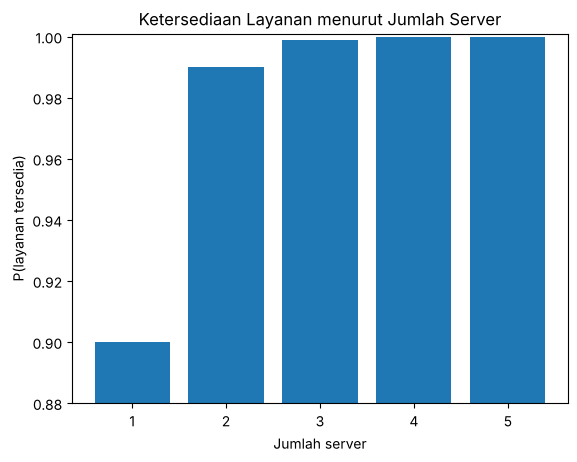

In [ ]:
# B.5 | Probabilitas Komplemen | Contoh 1: Ketersediaan Layanan dengan Tiga Server Cadangan
# library numpy: default_rng() membuat generator bilangan acak
rng = np.random.default_rng(42)

p_mati = 0.10
n_server = 3
p_semua_mati = p_mati ** n_server
p_tersedia = 1 - p_semua_mati
print("P(semua mati) =", round(p_semua_mati, 4))
print("P(tersedia)   =", round(p_tersedia, 4))

# Simulasi: 1.000.000 kali pengamatan tiga server
N = 1_000_000
# library numpy: rng.random() membangkitkan data acak
mati = rng.random((N, n_server)) < p_mati
# library numpy: .mean() menghitung dari array
print("Simulasi P(semua mati) =", mati.all(axis=1).mean())
# library numpy: .mean() menghitung dari array
print("Simulasi P(tersedia)   =", (~mati.all(axis=1)).mean())

# Grafik: ketersediaan menurut jumlah server
# library numpy: np.arange() operasi array
jumlah = np.arange(1, 6)
# library matplotlib: plt.bar() untuk grafik
plt.bar(jumlah, 1 - p_mati ** jumlah)
plt.ylim(0.88, 1.001)
# library matplotlib: plt.xlabel() untuk grafik
plt.xlabel("Jumlah server")
# library matplotlib: plt.ylabel() untuk grafik
plt.ylabel("P(layanan tersedia)")
# library matplotlib: plt.title() untuk grafik
plt.title("Ketersediaan Layanan menurut Jumlah Server")
# library matplotlib: plt.show() untuk grafik
plt.show()


## 6. Probabilitas Bersyarat
**Contoh 1: Klik Iklan Berdasarkan Jenis Perangkat**

Dari 200 pengguna yang melihat sebuah iklan, 120 memakai mobile dan 80 memakai desktop. Sebanyak 24 pengguna mobile dan 24 pengguna desktop mengeklik iklan. Satu pengguna dipilih secara acak.

In [ ]:
# B.6 | Probabilitas Bersyarat | Contoh 1: Klik Iklan Berdasarkan Jenis Perangkat
# Data 200 pengguna
# library pandas: DataFrame() membuat tabel data
data = pd.DataFrame({
    "perangkat": ["mobile"] * 120 + ["desktop"] * 80,
    "klik": ["ya"] * 24 + ["tidak"] * 96 + ["ya"] * 24 + ["tidak"] * 56,
})
# library pandas: crosstab() membuat tabel kontingensi
print(pd.crosstab(data["perangkat"], data["klik"], margins=True, margins_name="Total"))

n_S = len(data)
# library numpy: .sum() menghitung dari array
n_M = (data["perangkat"] == "mobile").sum()
# library numpy: .sum() menghitung dari array
n_K = (data["klik"] == "ya").sum()
# library numpy: .sum() menghitung dari array
n_MK = ((data["perangkat"] == "mobile") & (data["klik"] == "ya")).sum()

p_K_M = (n_MK / n_S) / (n_M / n_S)       # P(K | M) = P(M irisan K) / P(M)
p_M_K = (n_MK / n_S) / (n_K / n_S)       # P(M | K) = P(M irisan K) / P(K)
print("P(K | M) =", p_K_M)
print("P(M | K) =", p_M_K)

# Dua hari berturut-turut, saling bebas
p_dua_hari = p_K_M * p_K_M
print("P(K1 irisan K2 | M) =", round(p_dua_hari, 4))


klik       tidak  ya  Total
perangkat                  
desktop       56  24     80
mobile        96  24    120
Total        152  48    200
P(K | M) = 0.2
P(M | K) = 0.5
P(K1 irisan K2 | M) = 0.04


## 7. Probabilitas Total
**Contoh 1: Timeout Request pada Jaringan CDN Tiga Wilayah**

Sebuah layanan streaming memakai jaringan CDN di tiga wilayah. Sebanyak 50% request berasal dari Asia, 30% dari Eropa, dan 20% dari Amerika. Peluang sebuah request mengalami timeout adalah 2% untuk Asia, 3% untuk Eropa, dan 6% untuk Amerika. Satu request dipilih secara acak.

Kontribusi: {'Asia': np.float64(0.01), 'Eropa': np.float64(0.009), 'Amerika': np.float64(0.012)}
P(A) = 0.031 | dengan np.dot = 0.031


Simulasi P(A) = 0.0311
Simulasi P(A irisan B3) = 0.0121


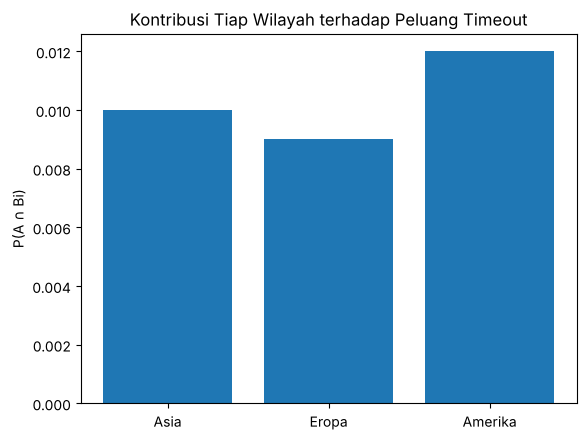

In [ ]:
# B.7 | Probabilitas Total | Contoh 1: Timeout Request pada Jaringan CDN Tiga Wilayah
# library numpy: default_rng() membuat generator bilangan acak
rng = np.random.default_rng(42)

wilayah = ["Asia", "Eropa", "Amerika"]
# library numpy: np.array() operasi array
p_B = np.array([0.50, 0.30, 0.20])             # P(Bi)
# library numpy: np.array() operasi array
p_A_B = np.array([0.02, 0.03, 0.06])           # P(A | Bi)

kontribusi = p_A_B * p_B                       # P(A irisan Bi)
# library numpy: .sum() menghitung dari array
p_A = kontribusi.sum()                         # peluang total
print("Kontribusi:", dict(zip(wilayah, kontribusi.round(4))))
# library numpy: np.dot() operasi array
print("P(A) =", round(p_A, 4), "| dengan np.dot =", round(np.dot(p_A_B, p_B), 4))

# Simulasi: 1.000.000 request
N = 1_000_000
# library numpy: rng.choice() membangkitkan data acak
w = rng.choice(3, size=N, p=p_B)
# library numpy: rng.random() membangkitkan data acak
timeout = rng.random(N) < p_A_B[w]
# library numpy: .mean() menghitung dari array
print("Simulasi P(A) =", round(timeout.mean(), 4))
# library numpy: np.mean() operasi array
# library numpy: .mean() menghitung dari array
print("Simulasi P(A irisan B3) =", round(np.mean((w == 2) & timeout), 4))

# Grafik: kontribusi tiap wilayah
# library matplotlib: plt.bar() untuk grafik
plt.bar(wilayah, kontribusi)
# library matplotlib: plt.ylabel() untuk grafik
plt.ylabel("P(A ∩ Bi)")
# library matplotlib: plt.title() untuk grafik
plt.title("Kontribusi Tiap Wilayah terhadap Peluang Timeout")
# library matplotlib: plt.show() untuk grafik
plt.show()


## 8. Teorema Bayes
**Contoh 1: Peringatan Scanner Malware**

Sebuah layanan penyimpanan awan memeriksa setiap file yang diunggah dengan scanner malware. Sebanyak 1% file yang diunggah benar-benar berisi malware. Jika file berisi malware, scanner memberi peringatan dengan peluang 95%. Jika file bersih, scanner tetap memberi peringatan palsu dengan peluang 3%.

In [ ]:
# B.8 | Teorema Bayes | Contoh 1: Peringatan Scanner Malware
# library numpy: default_rng() membuat generator bilangan acak
rng = np.random.default_rng(42)

p_M = 0.01          # P(M): file berisi malware
p_D_M = 0.95        # P(D | M): peringatan jika file berbahaya
p_D_Mc = 0.03       # P(D | M'): peringatan palsu jika file bersih

p_D = p_D_M * p_M + p_D_Mc * (1 - p_M)       # peluang total
p_M_D = p_D_M * p_M / p_D                    # teorema Bayes
print("P(D)     =", round(p_D, 4))
print("P(M | D) =", round(p_M_D, 4))

# Simulasi: 2.000.000 file
N = 2_000_000
# library numpy: rng.random() membangkitkan data acak
malware = rng.random(N) < p_M
# library numpy: rng.random() membangkitkan data acak
# library numpy: np.where() operasi array
peringatan = np.where(malware, rng.random(N) < p_D_M, rng.random(N) < p_D_Mc)
# library numpy: .mean() menghitung dari array
print("Simulasi P(D)     =", round(peringatan.mean(), 4))
# library numpy: .mean() menghitung dari array
print("Simulasi P(M | D) =", round(malware[peringatan].mean(), 4))


P(D)     = 0.0392
P(M | D) = 0.2423


Simulasi P(D)     = 0.0391
Simulasi P(M | D) = 0.242


## 9. Naive Bayes
**Contoh 1: Filter Spam pada Pesan Masuk**

Sebuah aplikasi pesan menyaring spam dari teks. Data latih berisi enam pesan. Tiga pesan spam adalah gratis menang hadiah klik, klik gratis hadiah, dan menang gratis klik hadiah. Tiga pesan bukan spam adalah rapat jadwal tim besok, kode proyek tim rapat, dan jadwal proyek besok. Sebuah pesan baru berbunyi gratis rapat klik.

In [ ]:
# B.9 | Naive Bayes | Contoh 1: Filter Spam pada Pesan Masuk
pesan = [
    "gratis menang hadiah klik", "klik gratis hadiah", "menang gratis klik hadiah",  # spam
    "rapat jadwal tim besok", "kode proyek tim rapat", "jadwal proyek besok",  # bukan spam
]
label = [1, 1, 1, 0, 0, 0]                  # 1 = spam, 0 = bukan spam
baru = ["gratis rapat klik"]

# Mengubah teks menjadi hitungan kata
# library scikit-learn: CountVectorizer mengubah teks menjadi hitungan kata
cv = CountVectorizer()
# library scikit-learn: CountVectorizer mengubah teks menjadi hitungan kata
X = cv.fit_transform(pesan)
print("Kosakata:", list(cv.get_feature_names_out()))

# Melatih Naive Bayes Multinomial dengan penghalusan Laplace (alpha = 1)
# library scikit-learn: MultinomialNB() membuat model Naive Bayes
model = MultinomialNB(alpha=1).fit(X, label)
# library scikit-learn: CountVectorizer mengubah teks menjadi hitungan kata
# library scikit-learn: model.predict_proba() pada model Naive Bayes
proba = model.predict_proba(cv.transform(baru))[0]
print("P(bukan spam) =", round(proba[0], 4))
print("P(spam)       =", round(proba[1], 4))
# library scikit-learn: CountVectorizer mengubah teks menjadi hitungan kata
# library scikit-learn: model.predict() pada model Naive Bayes
print("Kelas:", "spam" if model.predict(cv.transform(baru))[0] == 1 else "bukan spam")

# Pemeriksaan manual: 16 / (16 + 3)
print("Hitungan manual 16/19 =", round(16 / 19, 4))


Kosakata: ['besok', 'gratis', 'hadiah', 'jadwal', 'klik', 'kode', 'menang', 'proyek', 'rapat', 'tim']
P(bukan spam) = 0.1579
P(spam)       = 0.8421
Kelas: spam
Hitungan manual 16/19 = 0.8421
